---

# Exploratory Data Analysis

*By Aryan.*

This section explores valence and the features. We only use the training set here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv("train_clean.csv")
train_df["explicit"] = train_df["explicit"].astype(int)

NUM_COLS = ["duration_ms", "danceability", "energy", "loudness", "speechiness",
            "acousticness", "instrumentalness", "liveness", "tempo"]

print(train_df.shape)
print("Missing values:", train_df.isna().sum().sum())
print("Duplicate rows:", train_df.duplicated().sum())
train_df.describe().T.round(3)

(63138, 15)
Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
duration_ms,63138.0,231762.392,112150.196,15800.000,174720.000,215720.000,267519.250,4789026.000
explicit,63138.0,0.080,0.271,0.000,0.000,0.000,0.000,1.000
danceability,63138.0,0.564,0.174,0.051,0.450,0.576,0.693,0.983
energy,63138.0,0.638,0.255,0.000,0.459,0.679,0.857,1.000
key,63138.0,5.293,3.556,0.000,2.000,5.000,8.000,11.000
loudness,63138.0,-8.376,4.962,-42.044,-10.233,-7.184,-5.098,3.156
mode,63138.0,0.629,0.483,0.000,0.000,1.000,1.000,1.000
speechiness,63138.0,0.080,0.080,0.022,0.036,0.049,0.085,0.660
acousticness,63138.0,0.321,0.336,0.000,0.015,0.178,0.608,0.996
instrumentalness,63138.0,0.180,0.327,0.000,0.000,0.000,0.134,0.999


No missing values or duplicates are left after cleaning.

## 1. Valence

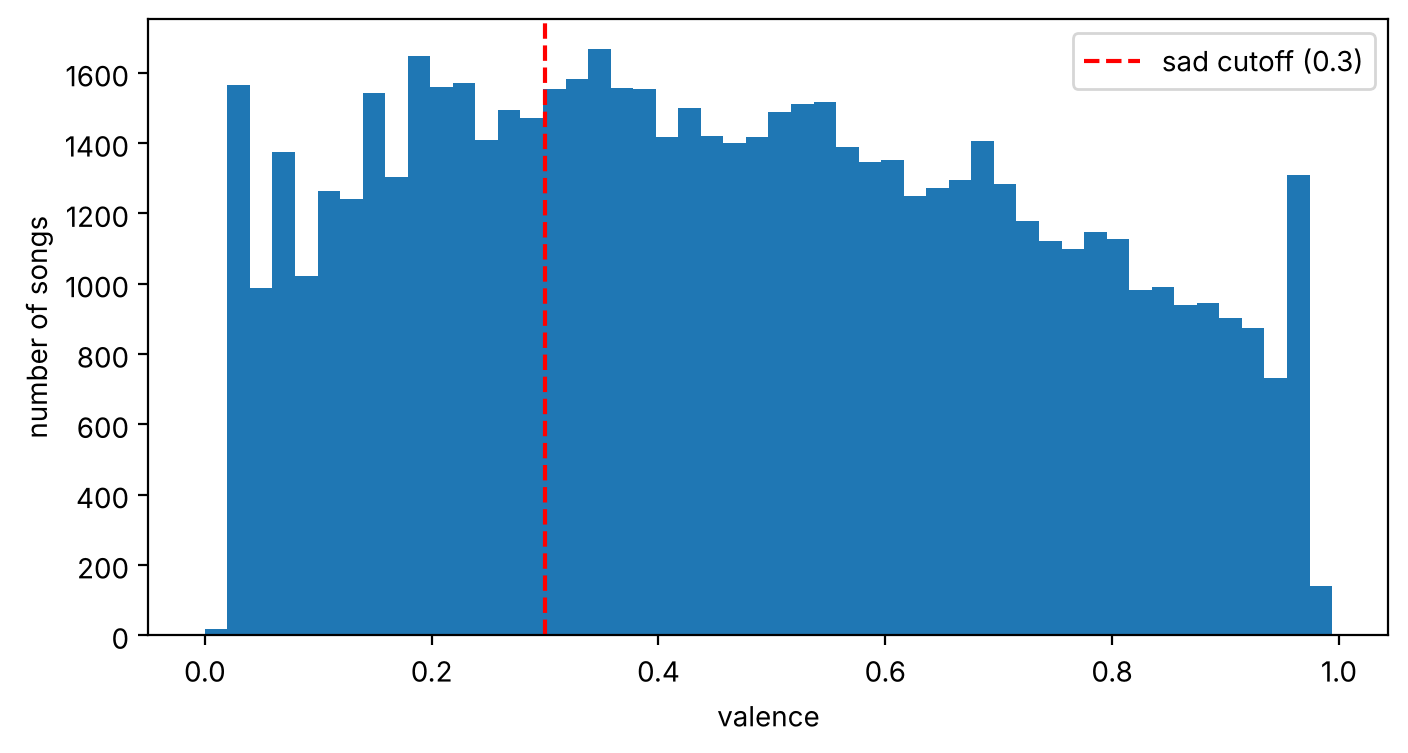

skew: 0.15
valence < 0.2: 19.1% of songs
valence < 0.3: 31.0% of songs
valence < 0.4: 43.7% of songs


In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_df["valence"], bins=50)
ax.axvline(0.3, color="red", ls="--", label="sad cutoff (0.3)")
ax.set_xlabel("valence")
ax.set_ylabel("number of songs")
ax.legend()
plt.show()

print(f"skew: {train_df['valence'].skew():.2f}")
for cutoff in [0.2, 0.3, 0.4]:
    print(f"valence < {cutoff}: {(train_df['valence'] < cutoff).mean():.1%} of songs")

Valence covers the whole 0 to 1 range and is barely skewed, so we don't need to transform it.
With a cutoff of 0.3, 31% of songs count as sad. The classes are imbalanced, so for classification we should look at F1 and ROC-AUC, not just accuracy.

## 2. Feature distributions

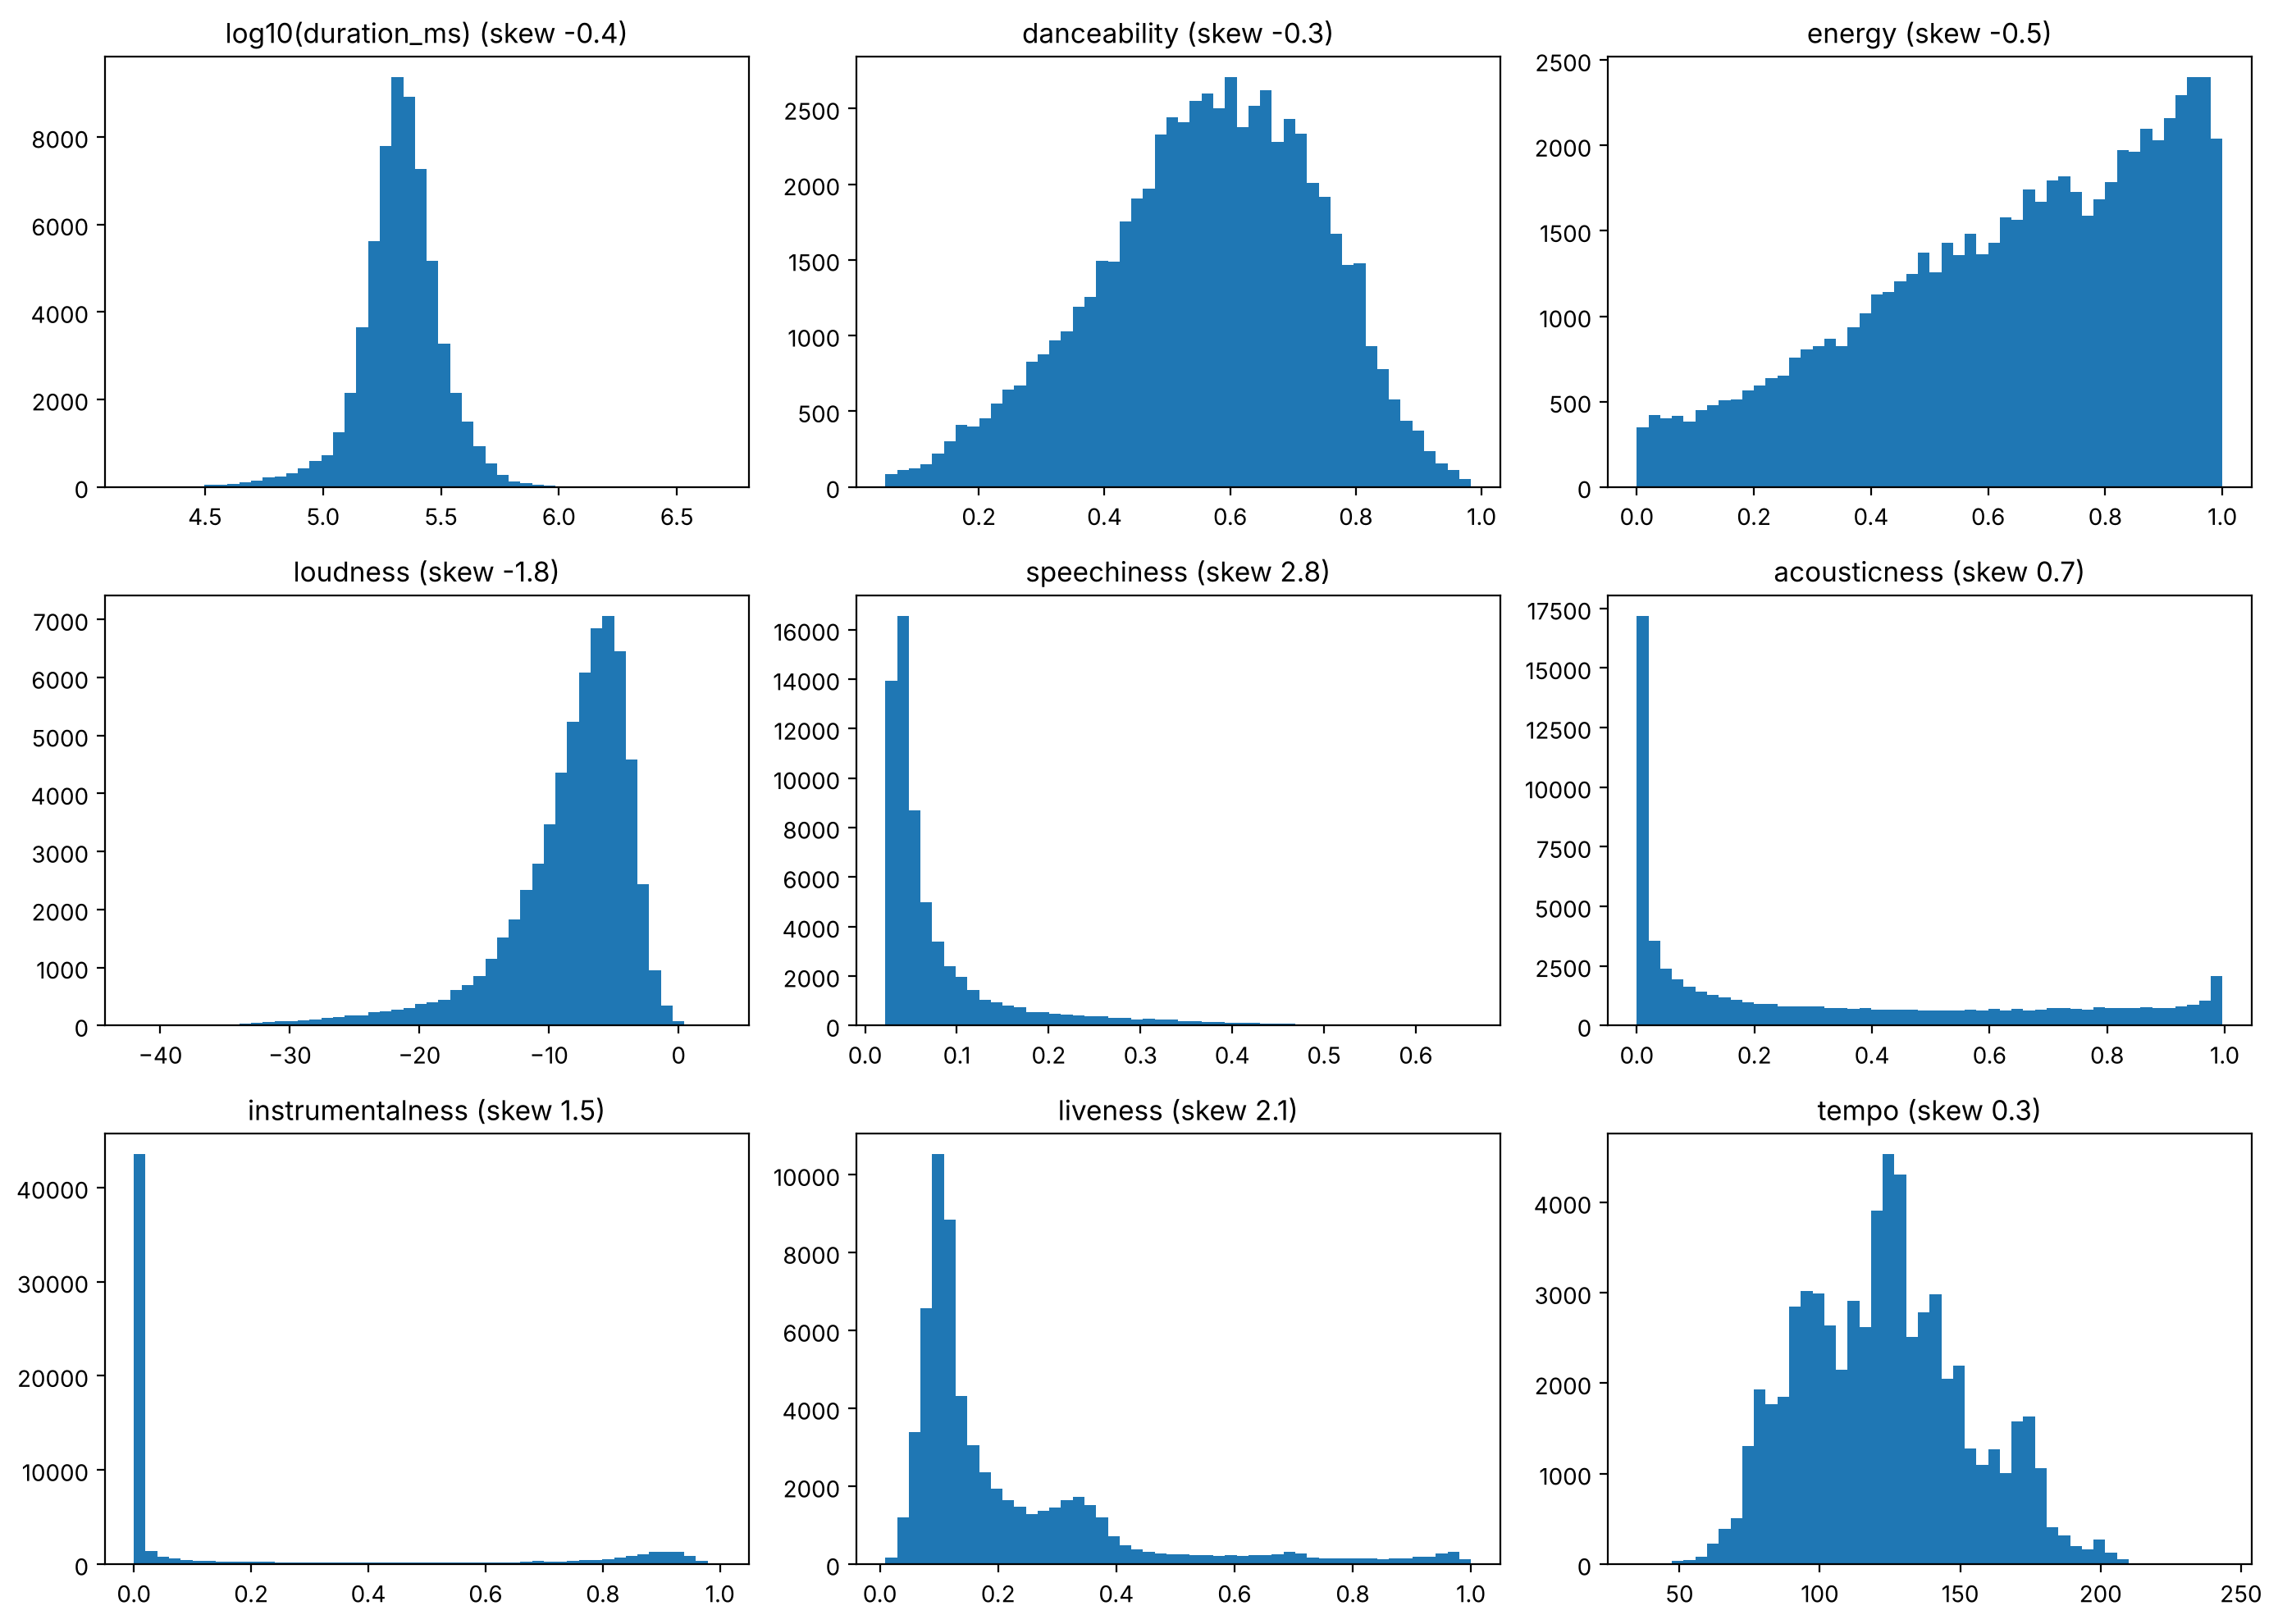

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, NUM_COLS):
    if col == "duration_ms":
        ax.hist(np.log10(train_df[col]), bins=50)
        ax.set_title(f"log10(duration_ms) (skew {np.log10(train_df[col]).skew():.1f})")
    else:
        ax.hist(train_df[col], bins=50)
        ax.set_title(f"{col} (skew {train_df[col].skew():.1f})")
plt.tight_layout()
plt.show()

In [4]:
print(f"duration_ms skew before log: {train_df['duration_ms'].skew():.1f}, songs over an hour: {(train_df['duration_ms'] > 3_600_000).sum()}")
print(f"instrumentalness < 0.01: {(train_df['instrumentalness'] < 0.01).mean():.1%} of songs")
for col in ["speechiness", "liveness"]:
    print(f"{col} skew: {train_df[col].skew():.1f} before log, {np.log(train_df[col]).skew():.1f} after log")

duration_ms skew before log: 10.2, songs over an hour: 8
instrumentalness < 0.01: 66.8% of songs
speechiness skew: 2.8 before log, 1.1 after log
liveness skew: 2.1 before log, 0.5 after log


`duration_ms` is very skewed (skew 10) because of a few very long tracks, including 8 over an hour. On a log scale it looks normal, so the plot shows log duration instead.
`liveness` and `speechiness` are also right-skewed. A log transform fixes liveness well but only helps speechiness a little.
`loudness` is skewed the other way, with a tail of very quiet songs. `acousticness` has a big spike at 0 and a smaller one near 1.
`instrumentalness` is almost 0 for two thirds of the songs, with a second group near 0.9, so it's almost a yes/no feature.

### Categorical features

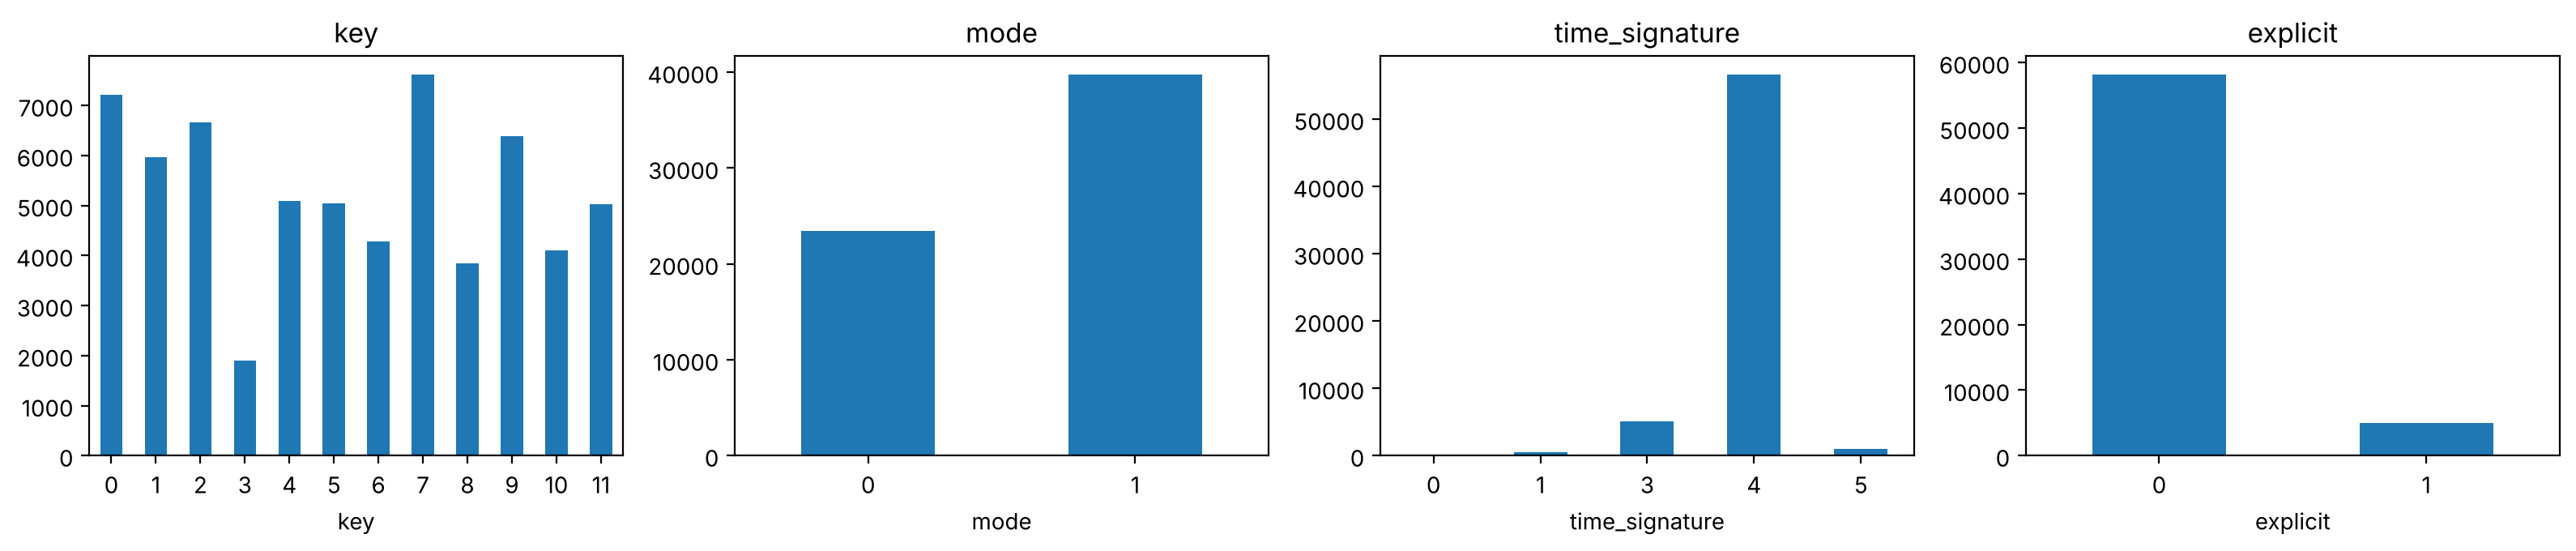

                count  mean
time_signature             
0                   4  0.39
1                 529  0.33
3                5048  0.35
4               56549  0.48
5                1008  0.37


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["key", "mode", "time_signature", "explicit"]):
    train_df[col].value_counts().sort_index().plot.bar(ax=ax, title=col)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(train_df.groupby("time_signature")["valence"].agg(["count", "mean"]).round(2))

Mode is 1 for major and 0 for minor. 63% of songs are major and 8% are explicit.
Almost 90% of songs are in 4/4 time. The other time signatures are rare (and 0 isn't a real time signature), but they all have lower valence than 4/4 (0.33 to 0.39 vs. 0.48). A single "is 4/4" feature may be more useful than the raw number.

## 3. Correlations

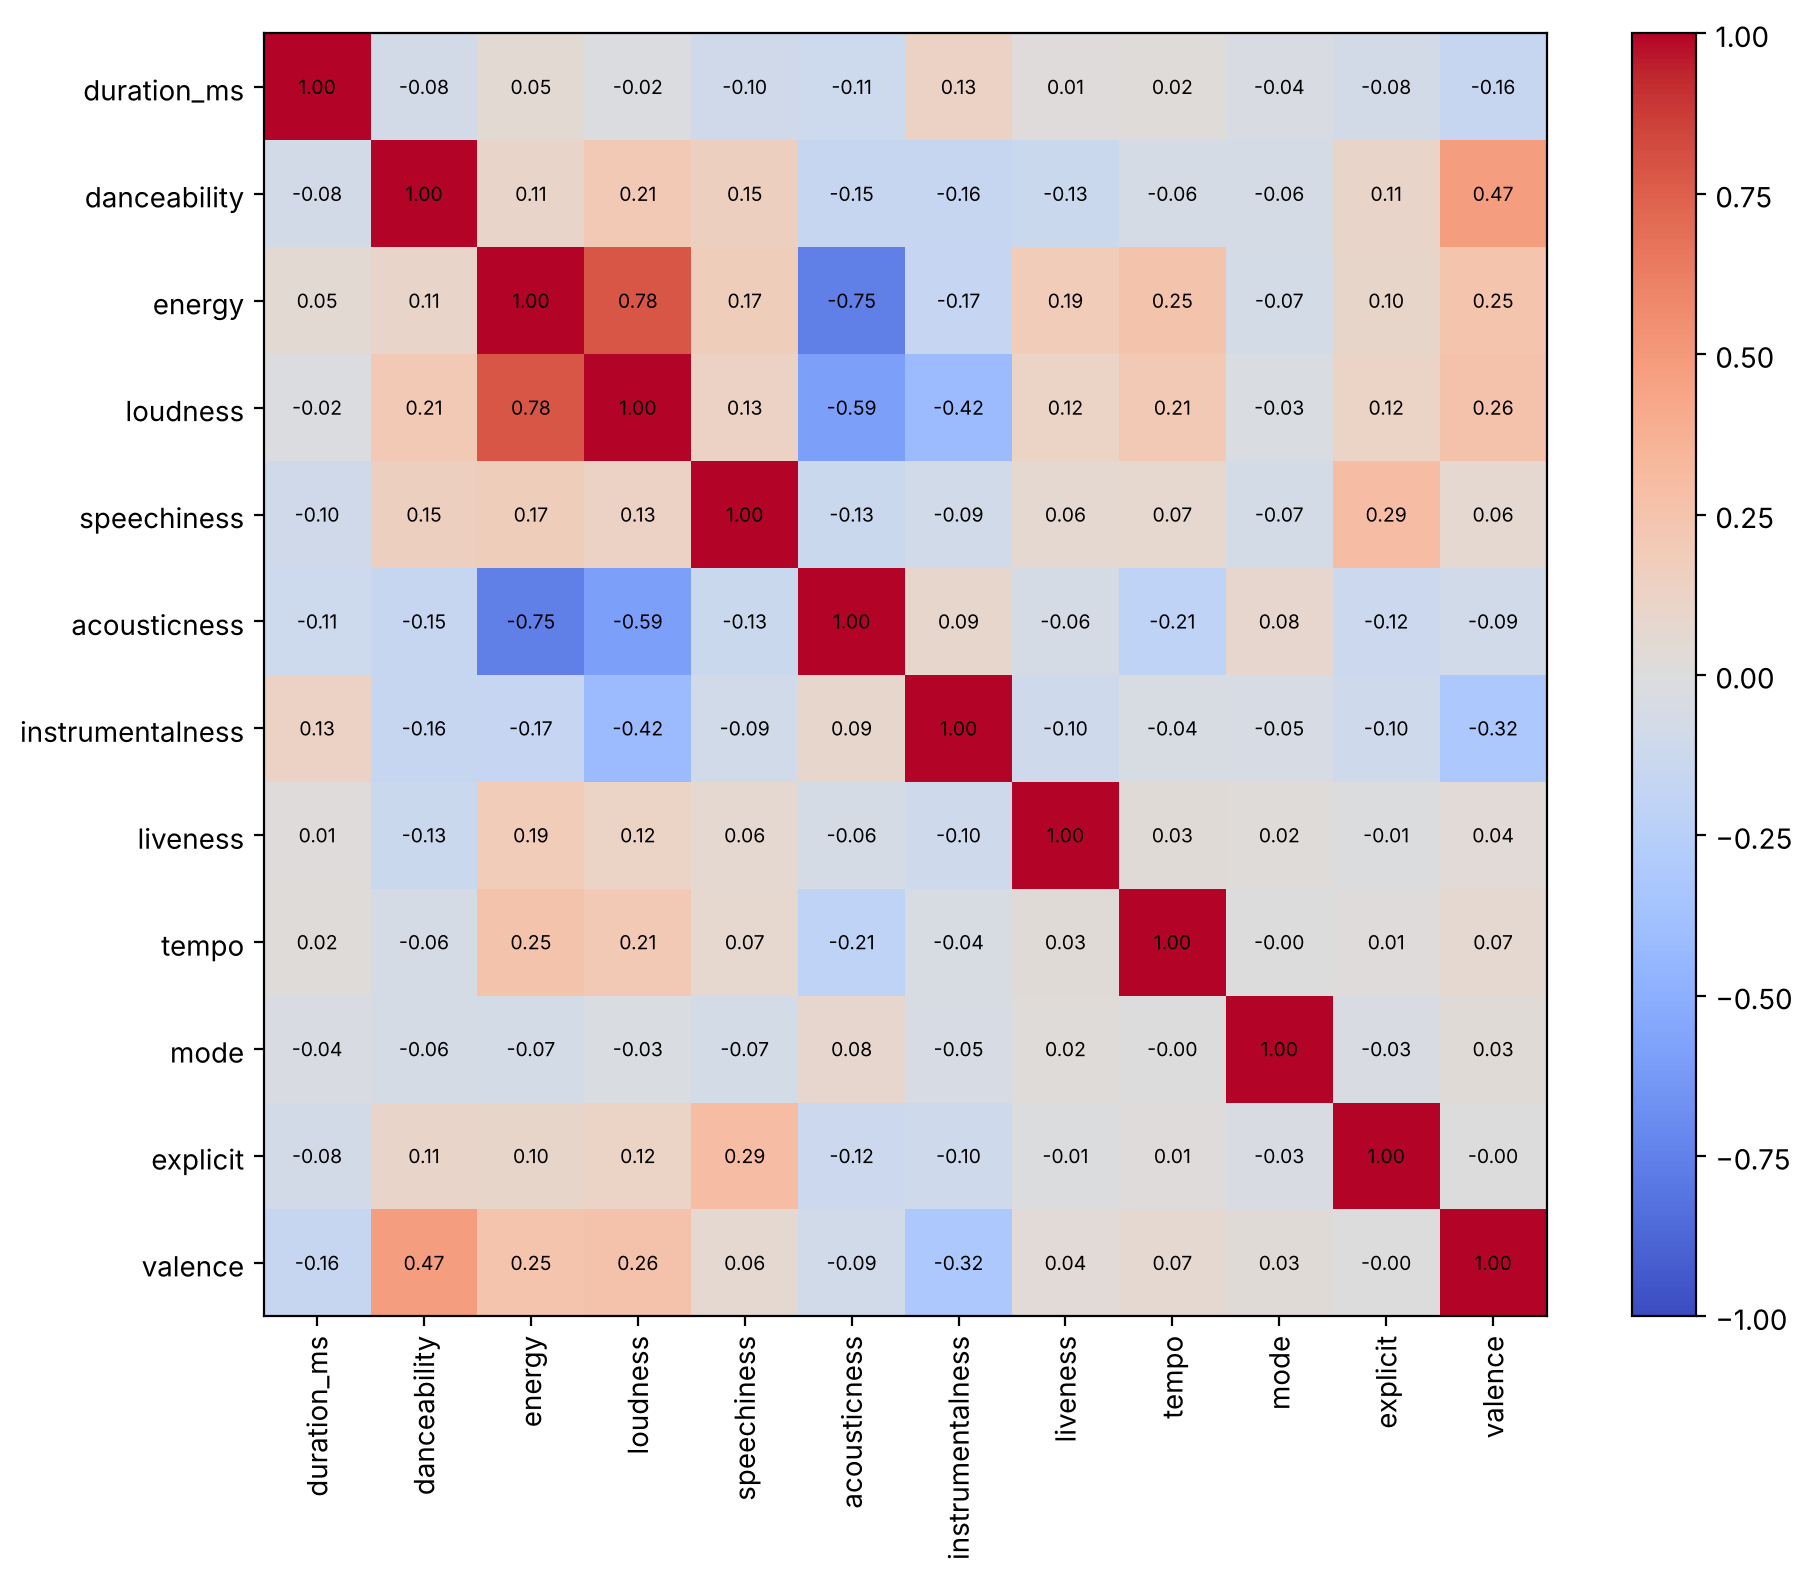

In [6]:
corr_cols = NUM_COLS + ["mode", "explicit", "valence"]
corr = train_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
plt.tight_layout()
plt.show()

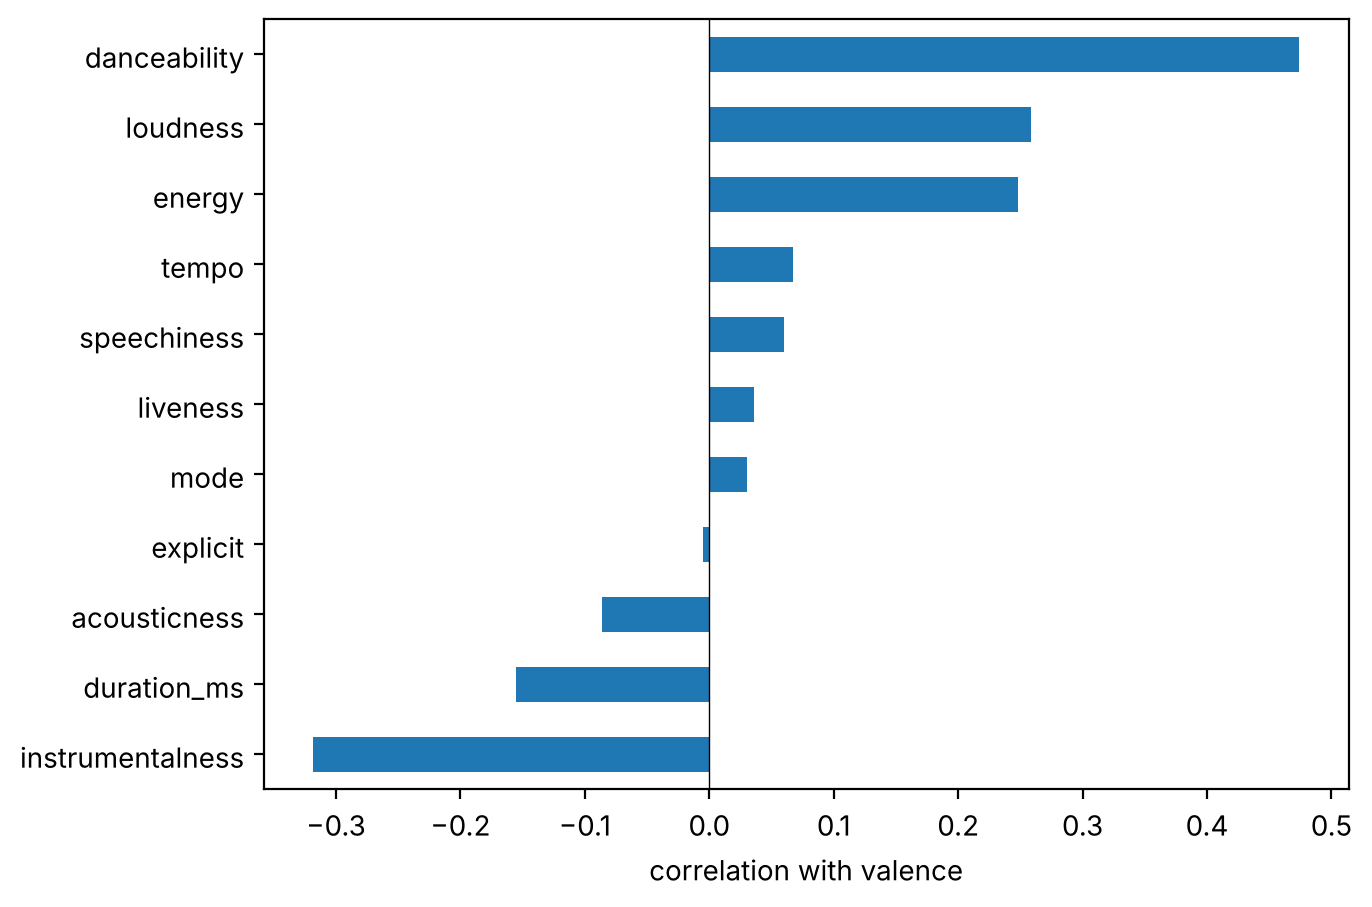

In [7]:
corr["valence"].drop("valence").sort_values().plot.barh(figsize=(7, 5))
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("correlation with valence")
plt.show()

Danceability has the strongest correlation with valence (0.47), followed by instrumentalness (−0.32), loudness (0.26), and energy (0.25). Mode and acousticness are close to 0.

Energy, loudness, and acousticness are strongly correlated with each other (energy and loudness 0.78, energy and acousticness −0.75), which makes their individual coefficients hard to interpret in a linear model.

## 4. Checking what we expected

We expected sad songs to be in a minor key, low energy, and acoustic.

In [8]:
print(train_df.groupby("mode")["valence"].agg(["mean", "median", "count"]).rename(index={0: "minor", 1: "major"}).round(3))

        mean  median  count
mode                       
minor  0.459   0.446  23425
major  0.475   0.461  39713


Minor-key songs are only slightly sadder than major-key songs (0.46 vs. 0.48 on average).

Next, we sort the songs by each feature, split them into 10 equal groups, and plot the average valence of each group.

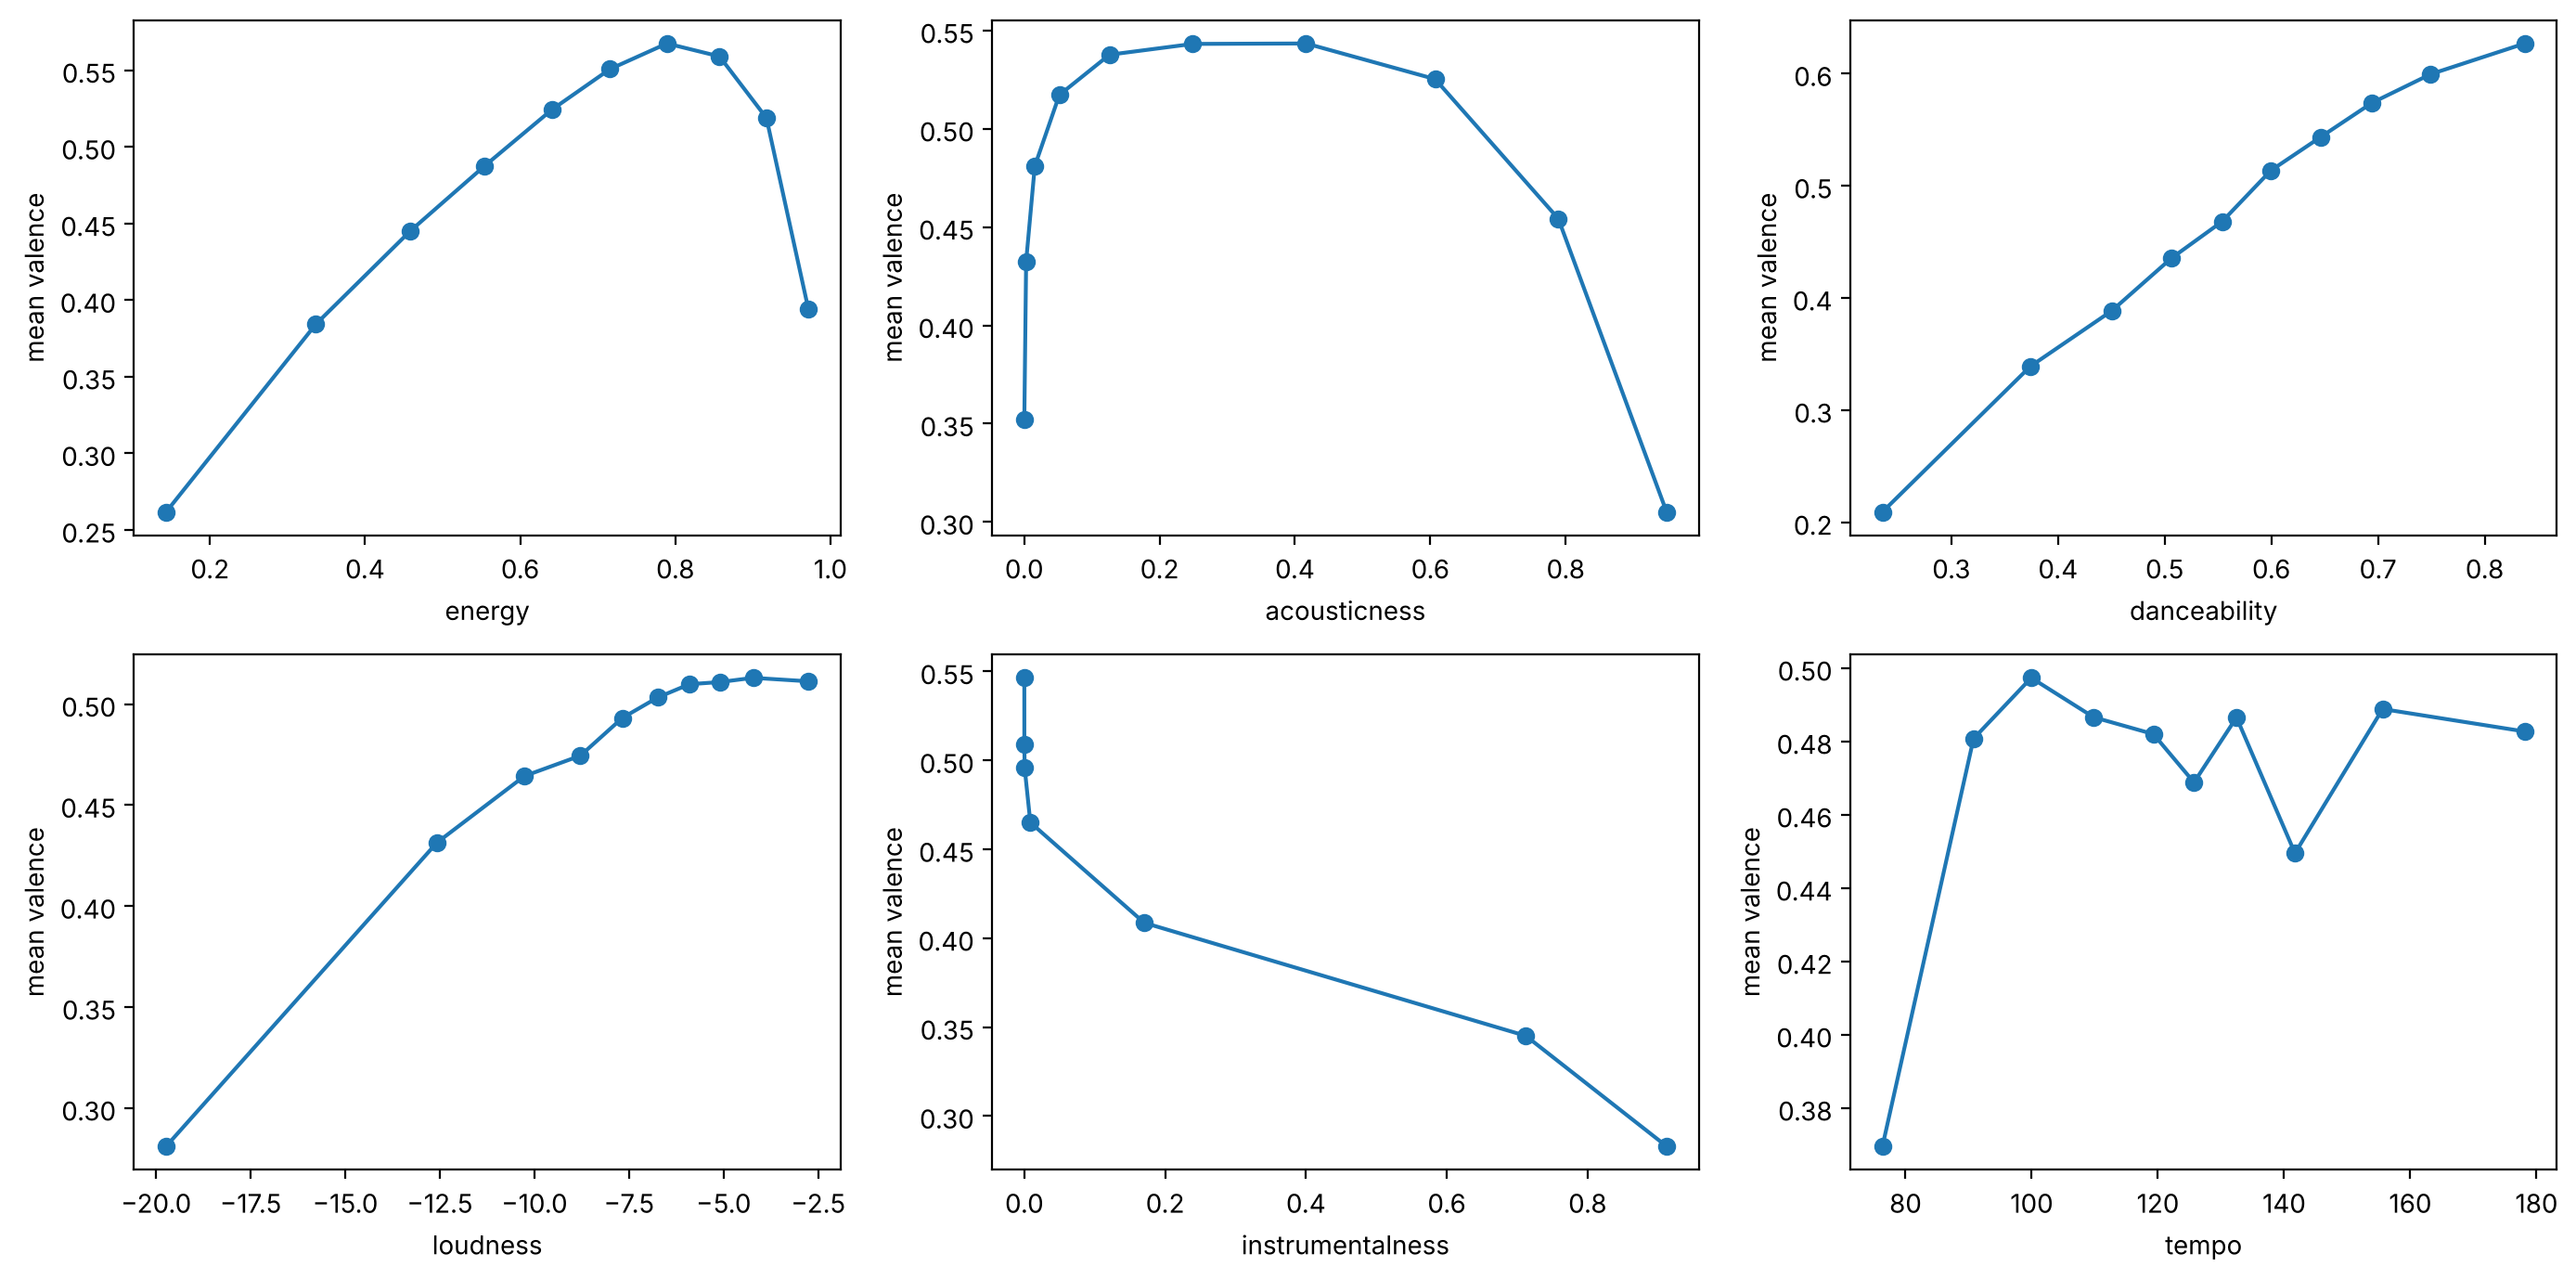

In [9]:
check_cols = ["energy", "acousticness", "danceability", "loudness", "instrumentalness", "tempo"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, check_cols):
    bins = pd.qcut(train_df[col], 10, duplicates="drop")
    means = train_df.groupby(bins, observed=True)["valence"].mean()
    centers = train_df.groupby(bins, observed=True)[col].mean()
    ax.plot(centers, means, marker="o")
    ax.set_xlabel(col)
    ax.set_ylabel("mean valence")
plt.tight_layout()
plt.show()

Valence goes up with energy until about 0.8, then drops sharply for the most energetic 10% of songs (from about 0.56 to 0.39). Very low and very high energy both go with lower valence.

Acousticness has an upside-down U shape. Songs with almost no acoustic sound and very acoustic songs are both sad, and the middle is happiest. This is why its correlation with valence is close to 0, even though it has a strong effect at both ends.

Danceability has a nearly straight-line relationship with valence, and loudness goes up and then levels off. Instrumentalness goes down, and tempo only matters for very slow songs.

Since energy and acousticness are curved, we check how much a squared term helps when predicting valence from each one alone.

In [10]:
def r2_poly(col, degree):
    coefs = np.polyfit(train_df[col], train_df["valence"], degree)
    pred = np.polyval(coefs, train_df[col])
    return 1 - ((train_df["valence"] - pred) ** 2).sum() / ((train_df["valence"] - train_df["valence"].mean()) ** 2).sum()

for col in ["energy", "acousticness"]:
    print(f"{col}: R² {r2_poly(col, 1):.3f} with a straight line, {r2_poly(col, 2):.3f} with a squared term")

instr = train_df["instrumentalness"] > 0.5
slow = train_df["tempo"] < 85
print(f"\ninstrumentalness > 0.5: {instr.mean():.0%} of songs, mean valence {train_df.loc[instr, 'valence'].mean():.2f} vs {train_df.loc[~instr, 'valence'].mean():.2f}")
print(f"tempo < 85: {slow.mean():.0%} of songs, mean valence {train_df.loc[slow, 'valence'].mean():.2f} vs {train_df.loc[~slow, 'valence'].mean():.2f}")

energy: R² 0.061 with a straight line, 0.113 with a squared term
acousticness: R² 0.007 with a straight line, 0.078 with a squared term

instrumentalness > 0.5: 19% of songs, mean valence 0.31 vs 0.51
tempo < 85: 10% of songs, mean valence 0.37 vs 0.48


The squared term almost doubles R² for energy and takes acousticness from almost no R² to 0.078.
Songs with instrumentalness above 0.5 average 0.31 valence vs. 0.51 for the rest, and songs under 85 BPM average 0.37 vs. 0.48.

## 5. Genre

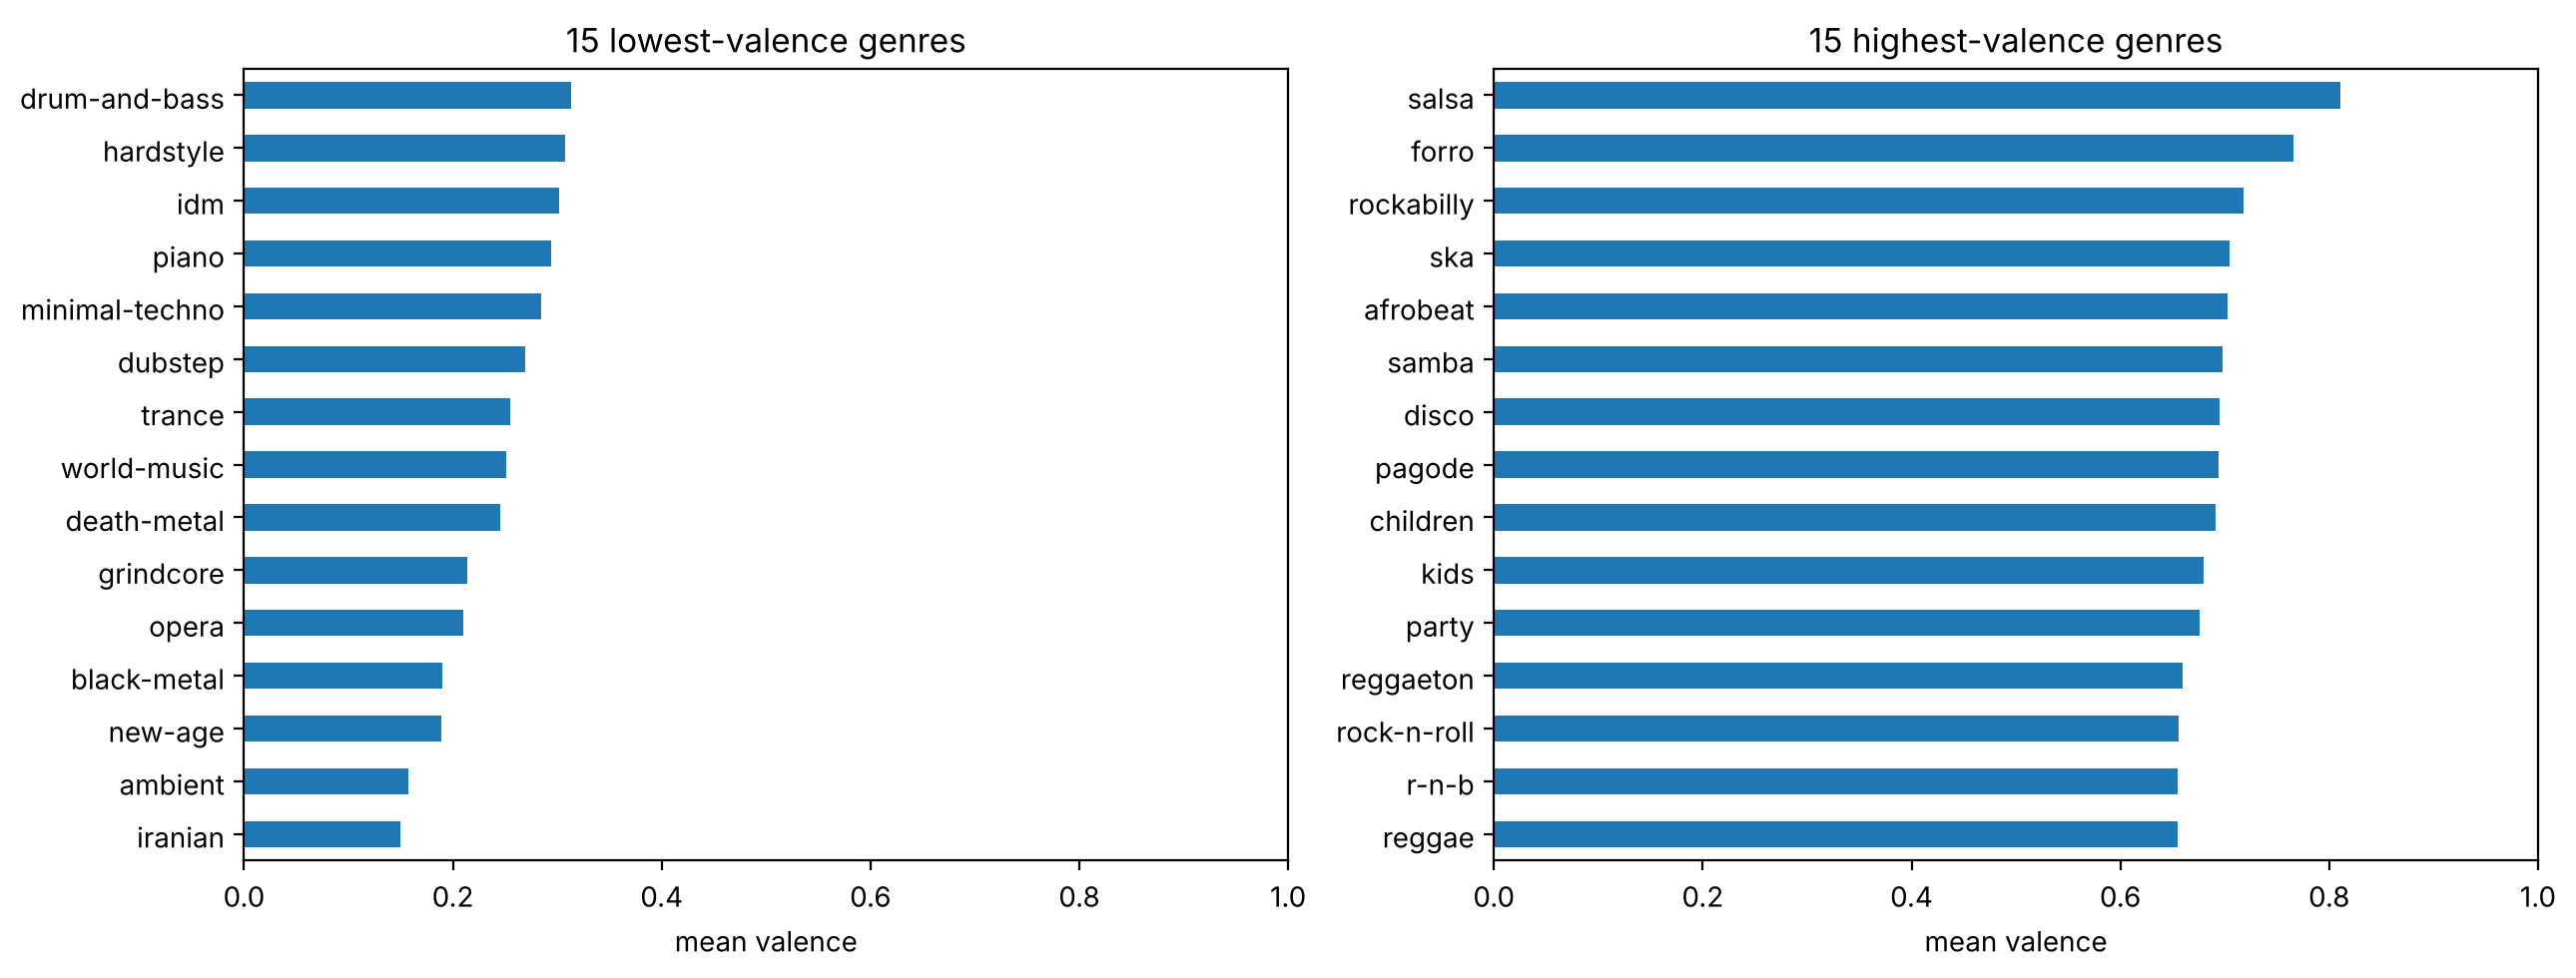

112 genres, mean valence from 0.15 to 0.81
R² from predicting each song as its genre's average: 0.32


In [11]:
genre_mean = train_df.groupby("track_genre")["valence"].mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
genre_mean.head(15).plot.barh(ax=axes[0], title="15 lowest-valence genres")
genre_mean.tail(15).plot.barh(ax=axes[1], title="15 highest-valence genres")
for ax in axes:
    ax.set_xlabel("mean valence")
    ax.set_ylabel("")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

genre_pred = train_df.groupby("track_genre")["valence"].transform("mean")
r2 = 1 - ((train_df["valence"] - genre_pred) ** 2).sum() / ((train_df["valence"] - train_df["valence"].mean()) ** 2).sum()
print(f"{train_df['track_genre'].nunique()} genres, mean valence from {genre_mean.min():.2f} to {genre_mean.max():.2f}")
print(f"R² from predicting each song as its genre's average: {r2:.2f}")

Average valence ranges from 0.15 (iranian) to 0.81 (salsa), and genre alone explains about a third of the variation in valence.

The lowest-valence genres fall into two groups, calm ones (ambient, new-age, opera, piano) and intense ones (black-metal, grindcore, death-metal, dubstep, hardstyle).

With 112 genres, one-hot encoding adds 112 columns. Target encoding (fit inside the cross-validation folds) or grouping genres into families would use fewer.

## 6. Sad vs. intense songs

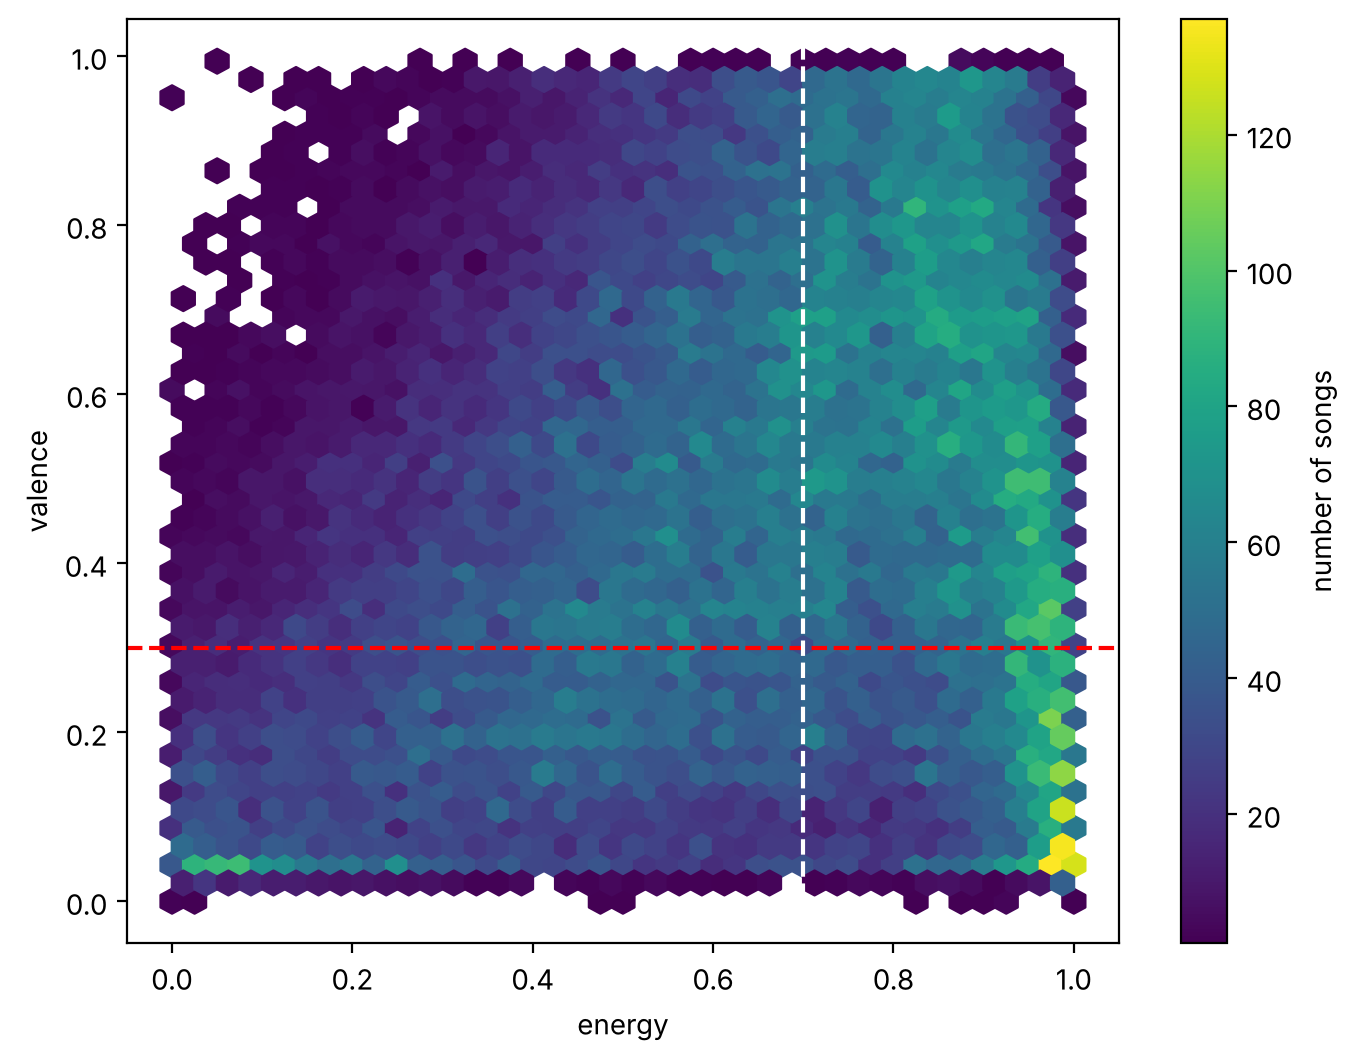

Sad songs with energy > 0.7: 37.6%
Sad songs with energy < 0.4: 34.0%

Genres with the most high-energy sad songs:
track_genre
grindcore        566
black-metal      524
death-metal      415
hardstyle        390
trance           365
drum-and-bass    358
happy            346
metalcore        292
iranian          231
club             221


In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(train_df["energy"], train_df["valence"], gridsize=40, mincnt=1, cmap="viridis")
ax.axhline(0.3, color="red", ls="--")
ax.axvline(0.7, color="white", ls="--")
ax.set_xlabel("energy")
ax.set_ylabel("valence")
fig.colorbar(hb, label="number of songs")
plt.show()

sad = train_df[train_df["valence"] < 0.3]
print(f"Sad songs with energy > 0.7: {(sad['energy'] > 0.7).mean():.1%}")
print(f"Sad songs with energy < 0.4: {(sad['energy'] < 0.4).mean():.1%}")
print("\nGenres with the most high-energy sad songs:")
print(sad[sad["energy"] > 0.7]["track_genre"].value_counts().head(10).to_string())

Most low-valence songs are either low energy or very high energy.
38% of songs below 0.3 valence have energy above 0.7, about the same as the share with energy below 0.4. The high-energy ones are mostly metal (grindcore, black-metal, death-metal, metalcore) and hard electronic music (hardstyle, trance, drum-and-bass).

Low valence covers two different kinds of songs, calm sad songs and intense ones. A model that assumes more energy means happier will predict the intense ones too high.

## 7. Feature engineering ideas

1. Log transform `duration_ms` and `liveness`.
2. Add squared terms for energy and acousticness, which have curved relationships with valence.
3. Add an "is instrumental" flag (`instrumentalness > 0.5`) and a "slow song" flag (`tempo < 85`).
4. Replace `time_signature` with an "is 4/4" flag, and treat `key` as a category instead of a number.
5. Encode genre with one-hot, target encoding, or genre families.
6. Try interaction terms like energy × danceability or energy × genre family, to help separate intense songs from happy energetic ones.